# 01 — Multimodal Document AI & Compliance Pipeline Demo

Demonstrates the decoupled compliance validation architecture over 100% synthetic Excel and PDF fixtures:
1. Classify & split multi-page PDF bundles (`PdfDocumentSplitter` with consolidated payroll retention vs. individual certificate splitting).
2. Extract worker & employer attributes via OCR cascade + structured extraction.
3. Evaluate deterministic statutory & safety compliance rules (`ComplianceEvaluator`).
4. Export sanitized audit Excel workbook (`>26` column safe via `get_column_letter`) and JSON summary.

In [1]:
from pathlib import Path
import sys
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from compliance_engine.config import load_config
from compliance_engine.pipelines.runner import CompliancePipelineRunner

cfg = load_config(repo_root=REPO_ROOT)
runner = CompliancePipelineRunner(cfg, use_cloud=False)
summary = runner.run_directory()

print(f"Processed Records: {summary.total_records}")
print(f"Approved:          {summary.approved_records}")
print(f"Rejected:          {summary.rejected_records}")
print(f"PDF Artifacts:     {summary.split_pdfs_generated}")

Processed Records: 4
Approved:          3
Rejected:          1
PDF Artifacts:     4


In [2]:
df_report = pd.read_excel(summary.output_excel_path, dtype=str)
df_report[["worker_id", "full_name", "payroll_status", "safety_status", "overall_status", "rejection_reason"]]

,worker_id,full_name,payroll_status,safety_status,overall_status,rejection_reason
0,901234561,Jane Doe,VALID,VALID,APPROVED (see observations),NO_ISSUES
1,901234562,Robert Smith,VALID,VALID,APPROVED (see observations),Not authorized for work at heights under Resol...
2,901234563,Elena Gomez,VALID,EXPIRED,APPROVED (see observations),Not authorized for work at heights: expired sa...
3,901234564,Marco Silva,MISSING_DOCUMENTS,MISSING_DOCUMENTS,REJECTED (see reason and observations),Access denied: no valid social-security paymen...


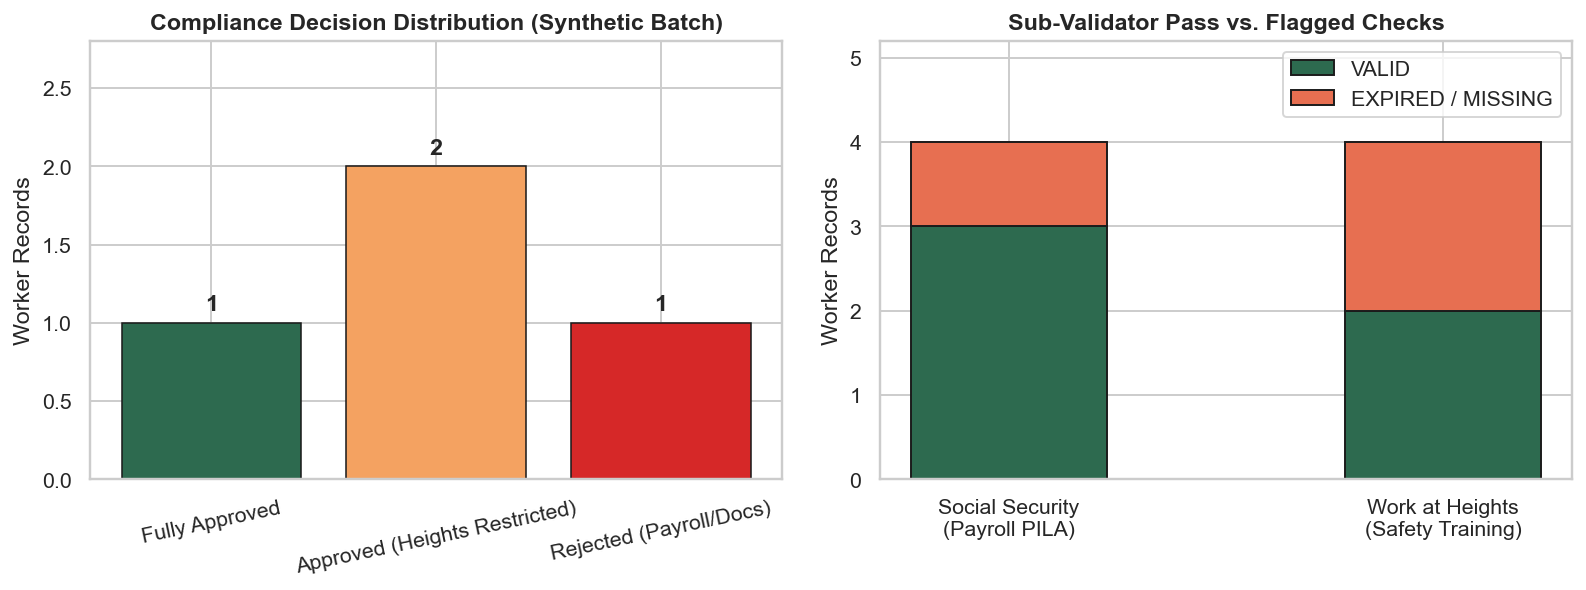

In [3]:
from IPython.display import Image, display
fig_path = cfg.figures_dir / "compliance_summary.png"
if fig_path.exists():
    display(Image(filename=str(fig_path)))